# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Araceli Soto Constancio, Fabrizzio Espinoza Andia, Kevin Teng, and Sam Leal

**Date:** 11/10/2026

In [16]:
# Your Phase 1 solution to the problem goes here.

#Part 1
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#reads in csv file and displays the first 5 rows
df = pd.read_csv('data/pierce_county_house_sales.csv')
df.head()

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [17]:
#inspecting the data types and null values in dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

In [18]:
#finds number of null values in each column
df.isnull().sum().sort_values(ascending=False)

waterfront_type                16261
view_quality                   15895
roof_cover                         8
hvac_description                   7
interior                           7
exterior                           1
sale_date                          0
house_square_feet                  0
sale_price                         0
detached_garage_square_feet        0
attic_finished_square_feet         0
fireplaces                         0
basement_square_feet               0
attached_garage_square_feet        0
stories                            0
bedrooms                           0
year_built                         0
bathrooms                          0
utility_sewer                      0
dtype: int64

In [19]:

#filling in null values for waterfront_type and view_quality with None
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
remaining = ["roof_cover", "hvac_description", "interior", "exterior"]
for x in remaining:
    df[x] = df[x].fillna("Unknown")
print("num of duplicate rows: ", df.duplicated().sum())

num of duplicate rows:  46


In [20]:
#drop duplicate rows
df = df.drop_duplicates()

#display summary statistics of the dataset
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sale_price,16768.0,461205.346255,236115.782503,2000.0,348000.0,416725.0,523881.50,6130000.0
house_square_feet,16768.0,1879.174082,760.438267,1.0,1320.0,1774.0,2351.25,9510.0
attic_finished_square_feet,16768.0,25.014313,102.197955,0.0,0.0,0.0,0.00,1212.0
basement_square_feet,16768.0,168.189408,429.462204,0.0,0.0,0.0,0.00,4000.0
attached_garage_square_feet,16768.0,364.218810,286.647006,0.0,0.0,420.0,528.00,2816.0
detached_garage_square_feet,16768.0,38.368022,164.878719,0.0,0.0,0.0,0.00,3664.0
fireplaces,16768.0,0.889552,0.596277,0.0,1.0,1.0,1.00,5.0
stories,16768.0,1.557371,0.512200,0.0,1.0,2.0,2.00,3.0
year_built,16768.0,1980.398318,33.332972,1880.0,1959.0,1990.0,2006.00,2021.0
bedrooms,16768.0,3.276419,0.891160,0.0,3.0,3.0,4.00,25.0


Text(0, 0.5, 'Sale Price')

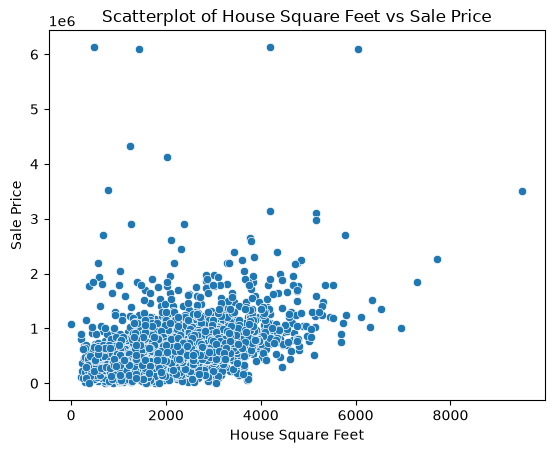

In [21]:
#visualizations
sns.scatterplot(data=df, x="house_square_feet", y="sale_price")
plt.title("Scatterplot of House Square Feet vs Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")

Text(0, 0.5, 'Frequency')

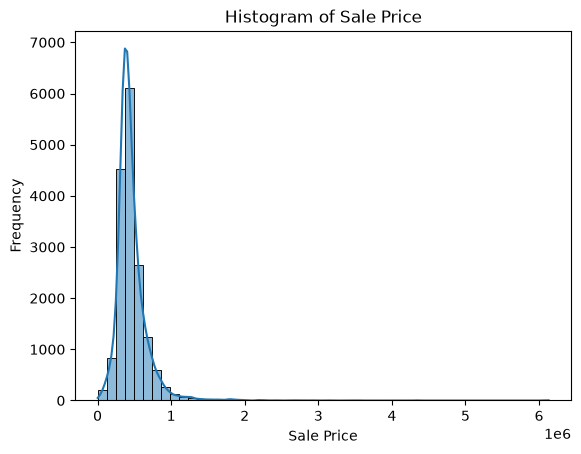

In [22]:
sns.histplot(data=df, x="sale_price", bins=50, kde=True)
plt.title("Histogram of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

In [23]:
#Part 2
#shows the categorical variables in the dataset
print("Categorical Variables: ", df.select_dtypes(include=['string']).columns)

#get sale year and drop date column
df["sale_year"] = pd.to_datetime(df["sale_date"]).dt.year
df = df.drop(columns=["sale_date"])

#hot encodes categorical variables  
encoded_df = pd.get_dummies(df, drop_first=True, dtype=int)

#check for missing values
encoded_df.isnull().sum().sort_values(ascending=False)

Categorical Variables:  Index(['sale_date', 'hvac_description', 'exterior', 'interior', 'roof_cover',
       'waterfront_type', 'view_quality', 'utility_sewer'],
      dtype='str')


sale_price                              0
house_square_feet                       0
attic_finished_square_feet              0
basement_square_feet                    0
attached_garage_square_feet             0
                                       ..
view_quality_View V-Good                0
utility_sewer_SEWER/SEPTIC AVAIL        0
utility_sewer_SEWER/SEPTIC INSTALLED    0
utility_sewer_SEWER/SEPTIC NO           0
utility_sewer_SEWER/SEPTIC NO PERC      0
Length: 61, dtype: int64

In [24]:
encoded_df.head()


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,...,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC AVAIL,utility_sewer_SEWER/SEPTIC INSTALLED,utility_sewer_SEWER/SEPTIC NO,utility_sewer_SEWER/SEPTIC NO PERC
0,380000,2157,0,0,528,0,0,2,1993,3,...,0,0,0,0,0,0,0,1,0,0
1,383000,2238,0,0,396,0,0,2,2017,4,...,0,0,0,0,0,0,0,1,0,0
2,419900,1452,0,0,0,0,1,1,1965,3,...,0,0,0,0,0,0,0,1,0,0
3,251660,832,0,0,0,0,0,1,1919,2,...,0,0,0,0,0,0,0,1,0,0
4,500000,1780,0,384,484,0,1,1,1955,3,...,0,0,0,0,0,0,0,1,0,0


In [25]:
#Part 3
from sklearn.model_selection import train_test_split

x = encoded_df.drop(columns=["sale_price"])
y = encoded_df["sale_price"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [26]:
#Part 4
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

#baseline model using only house_square_feet as the predictor variable
model = LinearRegression()
model.fit(x_train["house_square_feet"].values.reshape(-1, 1), y_train)

train_predictions = model.predict(x_train["house_square_feet"].values.reshape(-1, 1))
test_predictions = model.predict(x_test["house_square_feet"].values.reshape(-1, 1))

train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)

#second model using all predictor variables
model2 = LinearRegression()
model2.fit(x_train, y_train)

train_predictions2 = model2.predict(x_train)
test_predictions2 = model2.predict(x_test)

train_rmse2 = np.sqrt(mean_squared_error(y_train, train_predictions2))
test_rmse2 = np.sqrt(mean_squared_error(y_test, test_predictions2))
train_r2_2 = r2_score(y_train, train_predictions2)
test_r2_2 = r2_score(y_test, test_predictions2)

#third model using specific predictor variables
selected_features = ["house_square_feet","bathrooms", "bedrooms", "stories", "year_built"]
x_train_subset = x_train[selected_features]
x_test_subset = x_test[selected_features]

model3 = LinearRegression()
model3.fit(x_train_subset, y_train)

train_predictions3 = model3.predict(x_train_subset)
test_predictions3 = model3.predict(x_test_subset)

train_rmse3 = np.sqrt(mean_squared_error(y_train, train_predictions3))
test_rmse3 = np.sqrt(mean_squared_error(y_test, test_predictions3))
train_r2_3 = r2_score(y_train, train_predictions3)
test_r2_3 = r2_score(y_test, test_predictions3)

print("Train RMSE (model 1, model 2, model 3):", train_rmse, train_rmse2, train_rmse3)
print("Test RMSE (model 1, model 2, model 3):", test_rmse, test_rmse2, test_rmse3)
print("Train R2 (model 1, model 2, model 3):", train_r2, train_r2_2, train_r2_3)
print("Test R2 (model 1, model 2, model 3):", test_r2, test_r2_2, test_r2_3)

Train RMSE (model 1, model 2, model 3): 201314.86660581717 156979.27282764704 193693.61749479905
Test RMSE (model 1, model 2, model 3): 198890.83092830153 165720.2066102022 192907.4541699741
Train R2 (model 1, model 2, model 3): 0.278857551624503 0.5615157578425675 0.3324251216176749
Test R2 (model 1, model 2, model 3): 0.26660070331294783 0.49083106733514803 0.3100637179100175


Model 2, the model with all the features, has the best performance since it has the loweest test rmse and also the highest R2 value

C:\Users\kevin\AppData\Local\Temp\ipykernel_20136\4134755231.py:18: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  regression_model = sm.OLS(y_train.astype(float), sm.add_constant(x_train.astype(float))).fit()
c:\Users\kevin\DS3001\A01-data-wrangling\.venv\Lib\site-packages\statsmodels\graphics\regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
c:\Users\kevin\DS3001\A01-data-wrangling\.venv\Lib\site-packages\statsmodels\graphics\regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
c:\Users\kevin\DS3001\A01-data-wrangling\.venv\Lib\site-packages\statsmodels\graphics\regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely dete

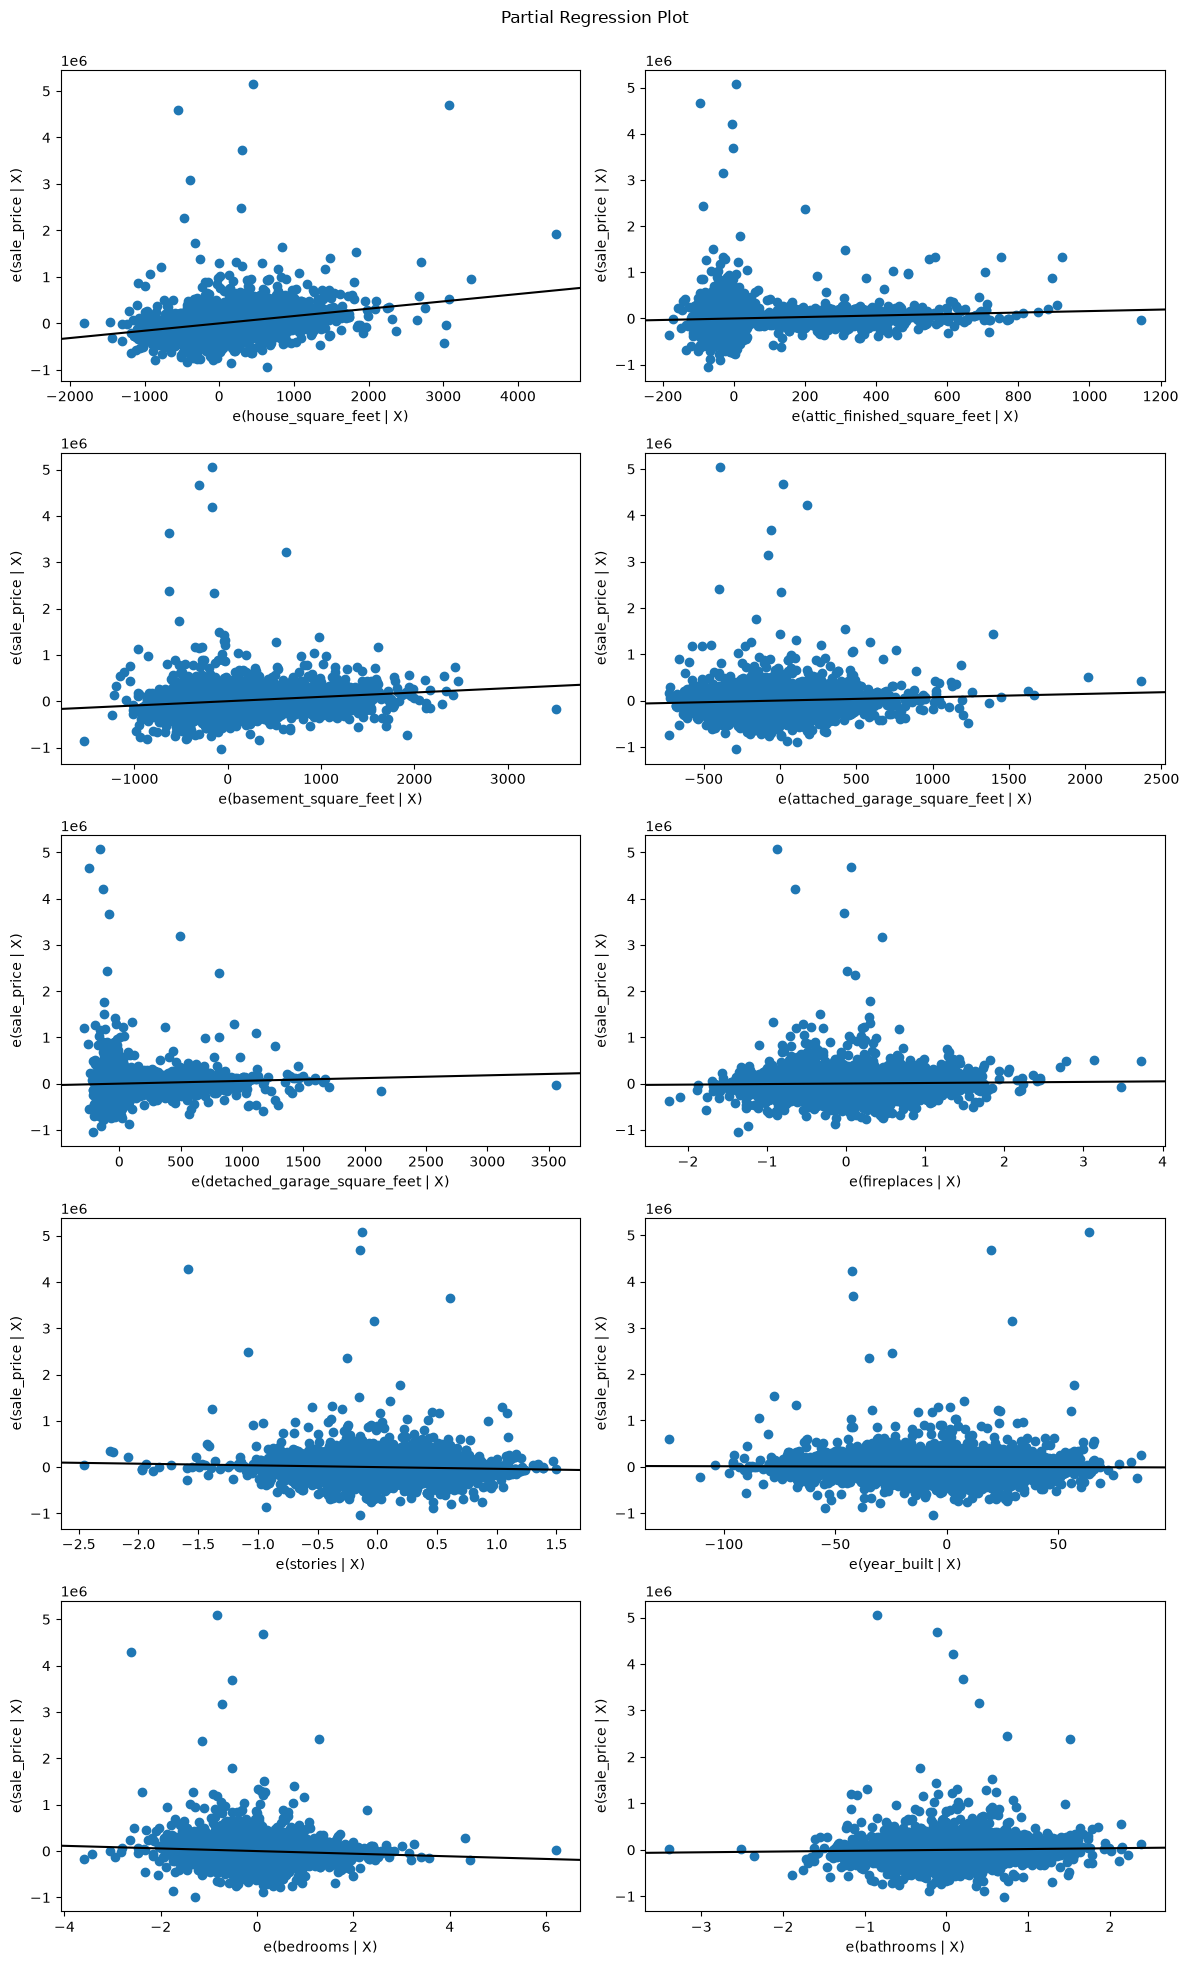

In [27]:
#Part 5
import statsmodels.api as sm
import matplotlib.pyplot as plt

numeric = [
   "house_square_feet",
   "attic_finished_square_feet",
   "basement_square_feet",
   "attached_garage_square_feet",
   "detached_garage_square_feet",
   "fireplaces",
   "stories",
   "year_built",
   "bedrooms",
   "bathrooms"
]

regression_model = sm.OLS(y_train.astype(float), sm.add_constant(x_train.astype(float))).fit()
sm.graphics.plot_partregress_grid(regression_model, exog_idx=numeric, fig=plt.figure(figsize=(12, 20)))
plt.show()



stories, year_built, bedrooms are possibly non linear. Stories curves up with the higher valeus in the middle forming an upwards curve. Year built shows a faint arch like pattern with hgih sale values on the left and right ned of the graph. Bedroom seems to have higher values concentrated to the left, forming a slight downward curve.

In [28]:
#part 6
x_train_transform = x_train.copy()
x_test_transform = x_test.copy()

#logarithmic transformations
x_train_transform["house_square_feet"] = np.log1p(x_train_transform["house_square_feet"])
x_test_transform["house_square_feet"] = np.log1p(x_test_transform["house_square_feet"])

#interactions
x_train_transform["size_bathrooms"] = x_train["house_square_feet"] * x_train["bathrooms"]
x_test_transform["size_bathrooms"] = x_test["house_square_feet"] * x_test["bathrooms"]

model4 = LinearRegression()
model4.fit(x_train_transform, y_train)
train_predictions4 = model4.predict(x_train_transform)
test_predictions4 = model4.predict(x_test_transform)

train_rmse4 = np.sqrt(mean_squared_error(y_train, train_predictions4))
test_rmse4 = np.sqrt(mean_squared_error(y_test, test_predictions4))
train_r2_4 = r2_score(y_train, train_predictions4)
test_r2_4 = r2_score(y_test, test_predictions4)

#transformed model
print("Train RMSE (Model 4):", train_rmse4)
print("Test RMSE (Model 4):", test_rmse4)
print("Train R2 (Model 4):", train_r2_4)
print("Test R2 (Model 4):", test_r2_4)

#best previous model
print("Train RMSE (Model 2):", train_rmse2)
print("Test RMSE (Model 2):", test_rmse2)
print("Train R2 (Model 2):", train_r2_2)
print("Test R2 (Model 2):", test_r2_2)


Train RMSE (Model 4): 157161.88287960453
Test RMSE (Model 4): 164745.22195248943
Train R2 (Model 4): 0.5604950090333825
Test R2 (Model 4): 0.49680464864213203
Train RMSE (Model 2): 156979.27282764704
Test RMSE (Model 2): 165720.2066102022
Train R2 (Model 2): 0.5615157578425675
Test R2 (Model 2): 0.49083106733514803


The model with transformations (model 4) performs slightly better since it reduces the test RMSE by around 1000 and test R² also increases by around 0.0066. The transformed model only provides a marginal improvement which suggests that adding more complexity does not improve the performance of the model significantly.

Part 7

After cleaning the dataset, I examined the house prices and encoded the categorical variables and created 3 regression models initially, before also creating a more complex model later.

Overall, model 1 performed the worst, then model 3, and the most performant was model 2 for the base models. This indicates that adding additional characteristics is significant in improving the performance of the model. Model 1 only used house square feet and performed poorly, indicating that square footage by itself is not enough to predict house prices. Model 3 adds on to that by adding some features, but also falls short with a slight performance increase. Model 2 performed the best of the three as it utilized all available features,  showing that using all characteristics improves performance the most. Though overall, model 4 performed the best, though only marginally to model 2, showing that adding interactions/transformations does not necessarily improve performance substantially.

Model 1 and 3 are underfitted as they have few predictor variables and thus are not able to capture more complex relationships between certain features and the sale price. They also have low training and testing R2 values. Model 2 and 4 could be overfit due to their higher training R2 values compared to the testing R2 values but the differences are not substantiable which indicates that the overfitting is not severe and is within a reasonable range. Overall, these results show that using more relevant predictors is the best way to improve improve, while adding more complexity can sometimes only net marginal improvements. 

In [29]:
#part 8
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_transform)
x_test_scaled = scaler.transform(x_test_transform)
lasso = LassoCV(cv=5, max_iter=100000, random_state=1)
lasso.fit(x_train_scaled, y_train)

selected_features = x_train_transform.columns[lasso.coef_ != 0]
print("Selected features:", selected_features)

train_predictions_lasso = lasso.predict(x_train_scaled)
test_predictions_lasso = lasso.predict(x_test_scaled)

print("Train RMSE (Lasso):", np.sqrt(mean_squared_error(y_train, train_predictions_lasso)))
print("Test RMSE (Lasso):", np.sqrt(mean_squared_error(y_test, test_predictions_lasso)))
print("Train R2 (Lasso):", r2_score(y_train, train_predictions_lasso))
print("Test R2 (Lasso):", r2_score(y_test, test_predictions_lasso))




Selected features: Index(['house_square_feet', 'attic_finished_square_feet',
       'basement_square_feet', 'attached_garage_square_feet',
       'detached_garage_square_feet', 'fireplaces', 'stories', 'bedrooms',
       'bathrooms', 'hvac_description_Heat Pump', 'hvac_description_No Heat',
       'hvac_description_Unknown', 'hvac_description_Warm and Cool Air Zone',
       'exterior_Cedar Finished Cabin', 'exterior_Cedar Unfinished Cabin',
       'exterior_Finished Cottage', 'exterior_Frame Rustic Log',
       'exterior_Frame Stucco', 'exterior_Frame Vinyl', 'exterior_Log',
       'exterior_Masonry Common Brick', 'exterior_Pine Finished Cabin',
       'exterior_Pine Unfinished Cabin', 'exterior_Unfinished Cottage',
       'exterior_Unknown', 'interior_Paneling',
       'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile',
       'roof_cover_Formed Seam Metal', 'roof_cover_Wood Shake',
       'waterfront_type_WF Lake', 'waterfront_type_WF River',
       'waterfront_type_WF Salt

The lasso model performs the best compared to the previous 4 models since total RMSE decreased from 166,136 to 165,000 and R2 increased from 0.4883 to 0.4952. However, Lasso has a higher training RMSE and a lower training R2 when compared to Model 4. The regularization helps with overfitting by putting less importance on the less useful predictors, thereby reducing the model from using noise in the training data and thus overfitting. The selected features are shown above.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** f820648f1aaa97747ef18a974f8dcd49af4cad6f
- **AI tool and model used:** GPT-6

### *Prompts used

1. based on the provided answers in phase 1 suggest a list of concise changes/improvements
2. explain how each proposed change can be implemented
3. sm.add_constant() for the change 4 causes an error, based on the error log how can I fix that error
4. Based on the provided rubric are there any other changes I should consider

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Question 1 - Data Cleaning: Modify the code to check for remaining missing values after filling waterfront_type and view_quality, and handle any remaining null values before modeling.

2. Question 2 - Categorical Variables: Change df.select_dtypes(include=['string']) to df.select_dtypes(include=['object', 'string', 'category']) to ensure all categorical variables are identified.

3. Question 4 - Linear Regression Models: Add a comparison table using the existing RMSE and R┬▓ calculations for Models 1ΓÇô3 to make it easier to identify the best-performing model.

4. Question 5 - Partial Regression Plots: Modify the statsmodels regression code to address the rank-deficient design matrix warning by removing linearly dependent columns before fitting the model.

5. Question 6 - Transformations and Interactions: Add polynomial transformations for stories, year_built, or bedrooms, which were identified as potentially nonlinear in Question 5, and compare their test RMSE and R┬▓ against Model 4.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | The existing code already checks for missing values and the output already confirms that there are no missing values left. This can be verified by checking encoded_df.isnull().sum().sort_values(ascending=False) which returns a list of features with missing values from highest to lowest and we can see that they are all 0.
| 2 | Reject | The current code already finds and encodes the categorical variables correctly so this change would not make a significant difference. This can be verified by comparing the categorical columns found using both approaches which shows that both produce the same result |
| 3 | Accept | A table would make the rmse and R2 values easier to compare between the three models. This can be verified by creating the table and checking to make sure the tables keep the same correct values and Model 2 remains as the most performant|
| 4 | Accept | The original code causes a SingularMatrixWarning so removing the linear dependent columns would improve the overall reliability of the code by fixing the issue and ensuring that the model can calculate the correct coefficients. To verify this we can rerun the regression and check that the warning disappears, there are no redundant columns, and all the numeric variables are still in the plot|
| 5 | Reject | The existing model already has some transformations and adding squared terms could make the model overly complicated without a significant performance boost. This can be verified by squaring the terms adn comparing the RMSE and R2 values to the original to determine if the transformations are worth using.|


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [30]:
# Your Phase 2 solution to the problem goes here.

#part 6 revised (suggestion 5)
# Copy original transformed datasets
x_train_new = x_train_transform.copy()
x_test_new = x_test_transform.copy()

# Add squared terms
for col in ["stories", "year_built", "bedrooms"]:
    x_train_new[col + "_squared"] = x_train[col] ** 2
    x_test_new[col + "_squared"] = x_test[col] ** 2

# Train new model
model5 = LinearRegression()
model5.fit(x_train_new, y_train)

# Predictions
train_predictions5 = model5.predict(x_train_new)
test_predictions5 = model5.predict(x_test_new)

# Calculate metrics
train_rmse5 = np.sqrt(mean_squared_error(y_train, train_predictions5))
test_rmse5 = np.sqrt(mean_squared_error(y_test, test_predictions5))
train_r2_5 = r2_score(y_train, train_predictions5)
test_r2_5 = r2_score(y_test, test_predictions5)

# Compare with original Model 4
print("Original Model 4:")
print("Test RMSE:", test_rmse4)
print("Test R2:", test_r2_4)

print("\nModel with Squared Terms:")
print("Test RMSE:", test_rmse5)
print("Test R2:", test_r2_5)

# Determine whether the change improved performance
if test_rmse5 < test_rmse4:
    print("\nSquared terms improved model performance.")
else:
    print("\nSquared terms did not improve model performance.")


Original Model 4:
Test RMSE: 164745.22195248943
Test R2: 0.49680464864213203

Model with Squared Terms:
Test RMSE: 186836.89384114073
Test R2: 0.3528033779097405

Squared terms did not improve model performance.


In [31]:

#Part 4 revised (suggestion 3)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

#baseline model using only house_square_feet as the predictor variable
model = LinearRegression()
model.fit(x_train["house_square_feet"].values.reshape(-1, 1), y_train)

train_predictions = model.predict(x_train["house_square_feet"].values.reshape(-1, 1))
test_predictions = model.predict(x_test["house_square_feet"].values.reshape(-1, 1))

train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)

#second model using all predictor variables
model2 = LinearRegression()
model2.fit(x_train, y_train)

train_predictions2 = model2.predict(x_train)
test_predictions2 = model2.predict(x_test)

train_rmse2 = np.sqrt(mean_squared_error(y_train, train_predictions2))
test_rmse2 = np.sqrt(mean_squared_error(y_test, test_predictions2))
train_r2_2 = r2_score(y_train, train_predictions2)
test_r2_2 = r2_score(y_test, test_predictions2)

#third model using specific predictor variables
selected_features = ["house_square_feet", "bathrooms", "bedrooms", "stories", "year_built"]
x_train_subset = x_train[selected_features]
x_test_subset = x_test[selected_features]

model3 = LinearRegression()
model3.fit(x_train_subset, y_train)

train_predictions3 = model3.predict(x_train_subset)
test_predictions3 = model3.predict(x_test_subset)

train_rmse3 = np.sqrt(mean_squared_error(y_train, train_predictions3))
test_rmse3 = np.sqrt(mean_squared_error(y_test, test_predictions3))
train_r2_3 = r2_score(y_train, train_predictions3)
test_r2_3 = r2_score(y_test, test_predictions3)

#compare model performance in a table
results = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Train RMSE": [train_rmse, train_rmse2, train_rmse3],
    "Test RMSE": [test_rmse, test_rmse2, test_rmse3],
    "Train R2": [train_r2, train_r2_2, train_r2_3],
    "Test R2": [test_r2, test_r2_2, test_r2_3]
})

display(results.round(4))


,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Model 1,201314.8666,198890.8309,0.2789,0.2666
1,Model 2,156979.2728,165720.2066,0.5615,0.4908
2,Model 3,193693.6175,192907.4542,0.3324,0.3101


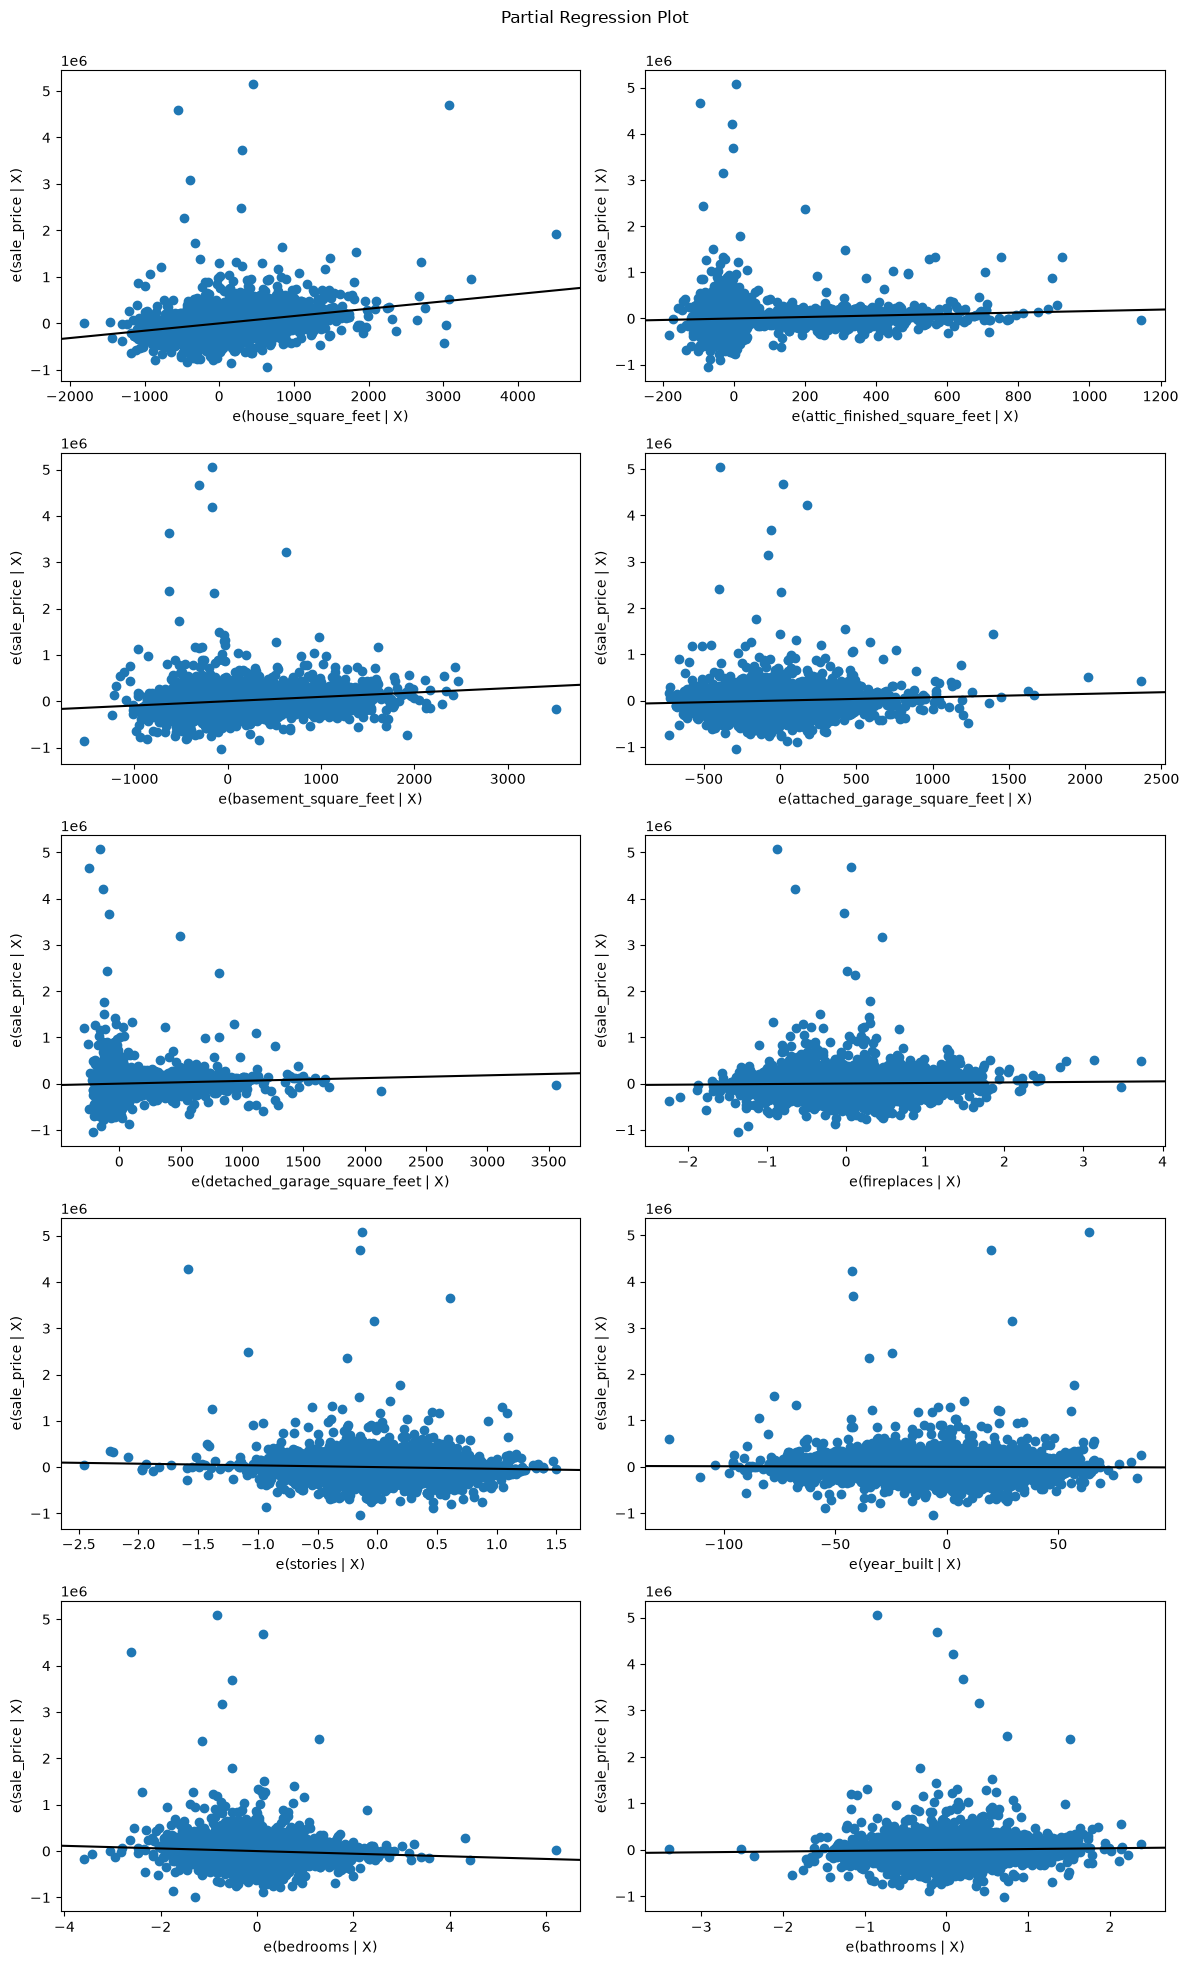

Original columns: 61
Remaining columns: 59
Removed columns: ['sale_year', 'exterior_Pine A-Frame']
All numeric variables included: True
Full column rank: True


In [32]:

#Part 5 Revised (Suggestion 4)
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np

numeric = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms"
]

# Create design matrix
X = sm.add_constant(x_train.astype(float), has_constant="add")

# Prioritize keeping the numeric variables
required = ["const"] + numeric
other = [col for col in X.columns if col not in required]

# Normalize columns for checking linear dependence
X_scaled = X / X.abs().max().replace(0, 1)

# Remove linearly dependent columns
selected = []
current_rank = 0

for col in required + other:
    test_cols = selected + [col]
    test_matrix = X_scaled[test_cols].to_numpy()

    new_rank = np.linalg.matrix_rank(test_matrix, tol=1e-10)

    if new_rank > current_rank:
        selected.append(col)
        current_rank = new_rank

# Keep independent columns
X = X[selected]

# Fit regression model
regression_model = sm.OLS(y_train.astype(float), X).fit()

# Generate partial regression plots
sm.graphics.plot_partregress_grid(
    regression_model,
    exog_idx=numeric,
    fig=plt.figure(figsize=(12, 20))
)
plt.show()

# Verify results
print("Original columns:", x_train.shape[1] + 1)
print("Remaining columns:", X.shape[1])
print("Removed columns:", [col for col in x_train.columns if col not in selected])
print("All numeric variables included:", all(col in X.columns for col in numeric))
print("Full column rank:", np.linalg.matrix_rank(X.to_numpy()) == X.shape[1])


### *Reflection on AI assistance
In your own words without generative AI.

The main improvements were related to code readability and overall reliability of the code. For example, one of the suggestions involved reorganizing the results from the regression into a table to make it easier to compare the RMSE and R2 across the three models. Another improvement focused on fixing the SingleMatrixWarning from part 5. Overall, these changes did not yield any significant performance in model performance, but focused on making the code easier to understand. The AI also showed some limitations. For example some of the proposed changes were unnecessary because the original code had already handled those particular issues correctly.The revised code for part 5 with AI assistance also initially caused a KeyError and the SingularMatrixWarning persisted. Overall, to verify the changes, I compared the original code results with the revised regression results to ensure that the regression stayed consistent. I also checked to make sure that the original warnings were correctly resolved in the revisions and that the partial regression had all of the correct numeric variables. A remaining concern 